<div style="display:block;width:100%;margin:auto;" direction=rtl align=center><br><br>
    <div  style="width:100%;margin:100;display:block;background-color:#fff0;"  display=block align=center>
        <table style="border-style:hidden;border-collapse:collapse;">             <tr>
                <td  style="border: none!important;">
                    <img width=130 align=right src="https://i.ibb.co/yXKQmtZ/logo1.png" style="margin:0;" />
                </td>
                <td style="text-align:center;border: none!important;">
                    <h1 align=center><font size=5 color="#045F5F"> <b>Armin Ghasemi</b><br><br>810100198</i></font></h1>
                </td>
                <td style="text-align:center;border: none!important;">
                    <h1 align=center><font size=5 color="#045F5F"> <b> computer vision </b><br><br>Final Project</i></font></h1>
                </td>
                <td style="text-align:center;border: none!important;">
                    <h1 align=center><font size=5 color="#045F5F"> <b>  </b><br><br></i></font></h1>
                </td>
                <td style="border: none!important;">
                    <img width=170 align=left  src="https://i.ibb.co/wLjqFkw/logo2.png" style="margin:0;" />
                </td>
           </tr>
        </table>
    </div>
</div>


# Part 1: Data Preparation Pipeline

This section focuses on the technical groundwork required to prepare the dataset for training.

**Objectives of this section:**
1.  **Efficient Retrieval:** Downloading and extracting the dataset using high-speed tools.
2.  **Structure Analysis:** Inspecting directory layouts and image properties to understand the input data.
3.  **Data Loading Strategy:** Implementing a high-performance data loader optimized for memory and speed.

## 1.1 Dataset Acquisition

We use the **Edges2Shoes** dataset from the Pix2Pix repository. Since the dataset is large, download speed is critical.

In the code below, we utilize `aria2`, a lightweight multi-protocol download utility. By using multiple connections (16 connections), we significantly accelerate the download process compared to standard `wget`. The dataset is then extracted, and a few samples are visualized to verify the content.

Installing aria2 for faster download...
Extracting archive...
Extraction complete.


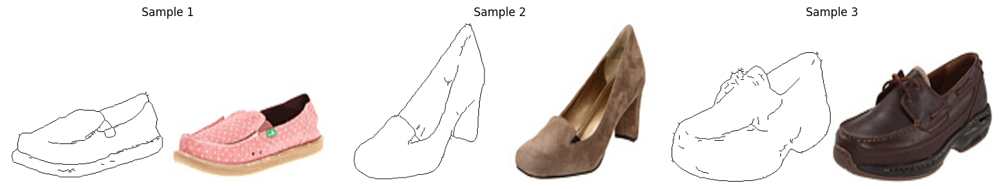

In [ ]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

# --- Configuration ---
DATASET_URL = 'http://efrosgans.eecs.berkeley.edu/pix2pix/datasets/edges2shoes.tar.gz'
ARCHIVE_NAME = 'edges2shoes.tar.gz'
DATASET_DIR = 'edges2shoes'

def download_and_extract():
    """
    Downloads the dataset using 'aria2' for maximum speed (multi-connection)
    and extracts it using 'tar'.
    """

    # 1. Install aria2 (High-speed download utility)
    # We use 'apt-get' inside Colab
    if os.system("which aria2c") != 0:
        print("Installing aria2 for faster download...")
        os.system("apt-get install -y aria2 > /dev/null")

    # 2. Download
    if not os.path.exists(ARCHIVE_NAME) and not os.path.exists(DATASET_DIR):
        print(f"Downloading {ARCHIVE_NAME} with aria2 (16 connections)...")
        # -x 16: 16 connections
        # -s 16: Split file into 16 parts
        # -q: Less verbose, but shows progress summary
        exit_code = os.system(f"aria2c -x 16 -s 16 {DATASET_URL} -o {ARCHIVE_NAME}")

        if exit_code != 0:
            print("Error: Download failed. Trying fallback to wget...")
            os.system(f"wget -c {DATASET_URL} -O {ARCHIVE_NAME}")
    else:
        print("Archive or Dataset already exists. Skipping download.")

    # 3. Extract
    if not os.path.exists(DATASET_DIR):
        print("Extracting archive...")
        # -z: Gzip
        # -x: Extract
        # -f: File
        os.system(f"tar -zxf {ARCHIVE_NAME}")
        print("Extraction complete.")

        # Optional: Remove archive to save space
        # os.remove(ARCHIVE_NAME)
    else:
        print("Dataset directory found. Skipping extraction.")

def visualize_samples(num_samples=3):
    """
    Pick random samples from the 'train' folder and display them.
    """
    train_path = os.path.join(DATASET_DIR, 'train')

    if not os.path.exists(train_path):
        print(f"Error: {train_path} not found.")
        return

    # Get list of all image files
    all_files = [f for f in os.listdir(train_path) if f.endswith('.jpg')]

    if not all_files:
        print("No images found in the dataset.")
        return

    # Select random images
    selected_files = random.sample(all_files, num_samples)

    # Plot
    plt.figure(figsize=(15, 5))
    for i, filename in enumerate(selected_files):
        img_path = os.path.join(train_path, filename)
        try:
            img = Image.open(img_path)
            plt.subplot(1, num_samples, i + 1)
            plt.imshow(img)
            plt.title(f"Sample {i+1}")
            plt.axis('off')
        except Exception as e:
            print(f"Could not load {filename}: {e}")

    plt.tight_layout()
    plt.show()

# --- Execution ---
if __name__ == "__main__":
    download_and_extract()
    visualize_samples()

## 1.2 Exploratory Data Analysis (EDA)

Before feeding data into the model, it is essential to understand its structure. We perform a quick inspection of the training and validation directories.

**Key Observations:**
* **Paired Structure:** The images are stored in a side-by-side format.
* **Resolution:** The total size is **256x512** pixels.
    * **Left Half (0-256):** The input edge map (Mask).
    * **Right Half (256-512):** The ground truth image (Real Photo).
* **Format:** The images are RGB with pixel values in the range [0, 255].

In [ ]:
import os
import numpy as np
from PIL import Image

# Configuration
DATASET_ROOT = './edges2shoes'
TRAIN_DIR = os.path.join(DATASET_ROOT, 'train')
VAL_DIR = os.path.join(DATASET_ROOT, 'val')

def inspect_directory(directory_path, subset_name):
    """
    Analyzes a specific directory (train/val) to report statistics.
    """
    if not os.path.exists(directory_path):
        print(f"Directory {subset_name} not found at {directory_path}")
        return

    # 1. Count images
    # Filtering for common image extensions to avoid counting system files
    valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp')
    files = [f for f in os.listdir(directory_path) if f.lower().endswith(valid_extensions)]
    total_count = len(files)

    print(f"--- {subset_name} Subset Analysis ---")
    print(f"Directory: {directory_path}")
    print(f"Total Images Found: {total_count}")

    if total_count > 0:
        # 2. Inspect the first image for dimensions and channels
        first_image_path = os.path.join(directory_path, files[0])
        try:
            img = Image.open(first_image_path)
            img_np = np.array(img)

            height, width, channels = img_np.shape

            print(f"Sample Image Resolution: {width}x{height}")
            print(f"Channels: {channels} (RGB)" if channels == 3 else f"Channels: {channels}")
            print(f"Data Type: {img_np.dtype}")
            print(f"Pixel Value Range: Min={img_np.min()}, Max={img_np.max()}")

            # 3. Verification of Paired Structure
            # We expect width to be 512 (256 for input + 256 for target)
            if width == 512 and height == 256:
                print("Structure Verification: PASSED (Dimensions match paired format 256x512)")
            else:
                print(f"Structure Verification: WARNING (Unexpected dimensions {width}x{height})")

        except Exception as e:
            print(f"Error reading sample image: {e}")
    else:
        print("No images found to analyze.")
    print("-" * 30)

# --- Main Execution ---

print("Starting Dataset Inspection...")

# Inspect Training Set
inspect_directory(TRAIN_DIR, "Training")

# Inspect Validation Set
inspect_directory(VAL_DIR, "Validation")

print("Inspection Complete.")

Starting Dataset Inspection...
--- Training Subset Analysis ---
Directory: ./edges2shoes/train
Total Images Found: 49825
Sample Image Resolution: 512x256
Channels: 3 (RGB)
Data Type: uint8
Pixel Value Range: Min=0, Max=255
Structure Verification: PASSED (Dimensions match paired format 256x512)
------------------------------
--- Validation Subset Analysis ---
Directory: ./edges2shoes/val
Total Images Found: 200
Sample Image Resolution: 512x256
Channels: 3 (RGB)
Data Type: uint8
Pixel Value Range: Min=0, Max=255
Structure Verification: PASSED (Dimensions match paired format 256x512)
------------------------------
Inspection Complete.


## 1.3 High-Performance Data Loading

To train the model efficiently, we implement a custom `Dataset` class named `FastBinaryDataset`.

**Design Choices:**
* **RAM Caching:** We load the **compressed binary bytes** of all images into RAM at initialization. This eliminates disk I/O bottlenecks during training.
* **No Augmentation:** As observed in Section 1.2, the training set contains approximately **50,000 images**. Given this substantial size, we proceed without data augmentation for this project.

**Processing Steps (`__getitem__`):**
1.  **Decode:** Convert binary bytes to an image array on the fly.
2.  **Split:** Separate the 256x512 image into `Input` (Edge) and `Target` (Shoe).
3.  **Normalize:** Scale pixel values to `[-1, 1]` to match the Generator's output range.

In [10]:
import os
import cv2
import numpy as np
import torch
import random
from torch.utils.data import Dataset

class FastBinaryDataset(Dataset):
    """
    Standard Dataset without Augmentation.
    Loads images into RAM for maximum speed.
    """
    def __init__(self, root_dir):
        self.root_dir = root_dir
        self.images_bytes = []

        if not os.path.exists(root_dir):
            raise FileNotFoundError(f"Directory {root_dir} does not exist.")

        # Load ALL files as BINARY bytes into RAM
        file_list = sorted([f for f in os.listdir(root_dir) if f.endswith('.jpg')])
        print(f"Loading {len(file_list)} images into RAM...")

        for fname in file_list:
            path = os.path.join(root_dir, fname)
            with open(path, 'rb') as f:
                self.images_bytes.append(f.read())

        print(f"Success! {len(self.images_bytes)} images loaded.")

    def __len__(self):
        return len(self.images_bytes)

    def __getitem__(self, idx):
        # 1. Decode
        file_bytes = np.frombuffer(self.images_bytes[idx], np.uint8)
        img = cv2.imdecode(file_bytes, cv2.IMREAD_COLOR)

        if img is None:
            return self.__getitem__(random.randint(0, len(self)-1))

        # 2. Convert to RGB
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # 3. Split (Assuming image is 256x512 -> creates two 256x256 images)
        h, w, c = img.shape
        w_half = w // 2
        img_A = img[:, :w_half, :] # Edge
        img_B = img[:, w_half:, :] # Shoe

        # 4. Normalize [-1, 1]
        img_A = (img_A.astype(np.float32) / 127.5) - 1.0
        img_B = (img_B.astype(np.float32) / 127.5) - 1.0

        # 5. Tensor
        input_tensor = torch.from_numpy(img_A.transpose(2, 0, 1))
        target_tensor = torch.from_numpy(img_B.transpose(2, 0, 1))

        return input_tensor, target_tensor

# Part 2: Model Architecture

In this project, we implement a Conditional GAN (cGAN) inspired by the **Pix2Pix** framework. This architecture is specifically designed for image-to-image translation tasks, where the model learns to map input pixels (edges) to output pixels (shoes).

To ensure the correctness of our implementation, we utilize **`torchinfo`** and **`torchview`** tools. These allow us to inspect the layer shapes and visually verify the connectivity of the networks.

## 2.1 The Generator (U-Net)

For the generator, we employ a **U-Net** architecture. Unlike a standard Autoencoder that loses spatial information, U-Net uses **Skip Connections**. These connections shuttle low-level features (like the exact position of edges) directly from the encoder to the decoder, ensuring that the generated shoe aligns perfectly with the input sketch.

The code below defines this architecture. As you will see in the **visualization block** following the class definition, the network takes a 3-channel input, compresses it into a bottleneck, and reconstructs it back to a 256x256 RGB image using the preserved features from the skip connections.

In [ ]:
import torch
import torch.nn as nn

class UNetDown(nn.Module):
    def __init__(self, in_channels, out_channels, normalize=True, dropout=0.0):
        super(UNetDown, self).__init__()
        layers = [nn.Conv2d(in_channels, out_channels, 4, 2, 1, bias=False)]
        if normalize:
            layers.append(nn.BatchNorm2d(out_channels))
        layers.append(nn.LeakyReLU(0.2))
        if dropout:
            layers.append(nn.Dropout(dropout))
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

class UNetUp(nn.Module):
    def __init__(self, in_channels, out_channels, dropout=0.0):
        super(UNetUp, self).__init__()
        layers = [
            nn.ConvTranspose2d(in_channels, out_channels, 4, 2, 1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        ]
        if dropout:
            layers.append(nn.Dropout(dropout))
        self.model = nn.Sequential(*layers)

    def forward(self, x, skip_input):
        x = self.model(x)
        # Concatenate skip connection
        x = torch.cat((x, skip_input), 1)
        return x

class GeneratorUNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=3):
        super(GeneratorUNet, self).__init__()

        # --- ENCODER ---
        self.down1 = UNetDown(in_channels, 64, normalize=False) # Out: 64
        self.down2 = UNetDown(64, 128)                          # Out: 128
        self.down3 = UNetDown(128, 256)                         # Out: 256
        self.down4 = UNetDown(256, 256)                         # Out: 256
        self.down5 = UNetDown(256, 256)                         # Out: 256
        self.down6 = UNetDown(256, 256)                         # Out: 256
        self.down7 = UNetDown(256, 256)                         # Out: 256
        self.down8 = UNetDown(256, 256, normalize=False)        # Out: 256 (Bottleneck)

        # --- DECODER ---

        # Up1: Input comes from down8 (256).
        # Output conv: 256. Concat with down7 (256). Total Out: 512
        self.up1 = UNetUp(256, 256, dropout=0.5) 

        # Up2: Input 512. Output conv: 256. Concat with down6 (256). Total Out: 512
        self.up2 = UNetUp(512, 256, dropout=0.5)

        # Up3: Input 512. Output conv: 256. Concat with down5 (256). Total Out: 512
        self.up3 = UNetUp(512, 256, dropout=0.5)

        # Up4: Input 512. Output conv: 256. Concat with down4 (256). Total Out: 512
        self.up4 = UNetUp(512, 256, dropout=0.5)

        # Up5: Input 512. Output conv: 128. Concat with down3 (256). Total Out: 384
        self.up5 = UNetUp(512, 128)

        # Up6: Input 384. Output conv: 64. Concat with down2 (128). Total Out: 192
        self.up6 = UNetUp(384, 64) 

        # Up7: Input 192. Output conv: 64. Concat with down1 (64). Total Out: 128
        self.up7 = UNetUp(192, 64) 

        # Final: Input 128 -> Output 3
        self.final = nn.Sequential(
            nn.Upsample(scale_factor=2),
            nn.ZeroPad2d((1, 0, 1, 0)),
            nn.Conv2d(128, out_channels, 4, padding=1), 
            nn.Tanh()
        )

    def forward(self, x):
        d1 = self.down1(x)
        d2 = self.down2(d1)
        d3 = self.down3(d2)
        d4 = self.down4(d3)
        d5 = self.down5(d4)
        d6 = self.down6(d5)
        d7 = self.down7(d6)
        d8 = self.down8(d7)

        u1 = self.up1(d8, d7)
        u2 = self.up2(u1, d6)
        u3 = self.up3(u2, d5)
        u4 = self.up4(u3, d4)
        u5 = self.up5(u4, d3)
        u6 = self.up6(u5, d2)
        u7 = self.up7(u6, d1)

        return self.final(u7)


In [ ]:
!pip install torchinfo torchview graphviz

Generating textual summary with torchinfo...
Layer (type:depth-idx)                   Input Shape               Output Shape              Param #                   Kernel Shape              Mult-Adds
GeneratorUNet                            [1, 3, 256, 256]          [1, 3, 256, 256]          --                        --                        --
├─UNetDown: 1-1                          [1, 3, 256, 256]          [1, 64, 128, 128]         --                        --                        --
│    └─Sequential: 2-1                   [1, 3, 256, 256]          [1, 64, 128, 128]         --                        --                        --
│    │    └─Conv2d: 3-1                  [1, 3, 256, 256]          [1, 64, 128, 128]         3,072                     [4, 4]                    50,331,648
│    │    └─LeakyReLU: 3-2               [1, 64, 128, 128]         [1, 64, 128, 128]         --                        --                        --
├─UNetDown: 1-2                          [1, 64, 128

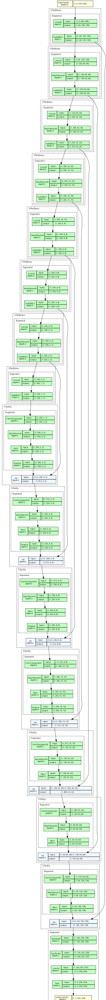

In [12]:
import torch
from torchinfo import summary
from torchview import draw_graph
import graphviz

# 1. Instantiate the Model
model = GeneratorUNet()

# --- Part A: Textual Summary using torchinfo ---
print("Generating textual summary with torchinfo...")

# We need to specify the input size (Batch_Size, Channels, H, W)
# Batch size 1 is enough for summary
summary_str = summary(
    model,
    input_size=(1, 3, 256, 256),
    col_names=["input_size", "output_size", "num_params", "kernel_size", "mult_adds"],
    verbose=0
)
print(summary_str)

# --- Part B: Visual Diagram using torchview ---
print("\nGenerating visual diagram with torchview...")

# This generates a graphviz object
model_graph = draw_graph(
    model,
    input_size=(1, 3, 256, 256),
    expand_nested=True,      # Expands the internal blocks (UNetDown/Up) to see layers
    save_graph=True,         # Saves a PDF/PNG file locally
    filename="generator_architecture",
    graph_dir="."            # Save in current directory
)

# Display the graph directly in the notebook
model_graph.visual_graph

## 2.2 The Discriminator (PatchGAN)

The discriminator aims to distinguish between real and generated images. Following the Pix2Pix approach, we implement a **PatchGAN** architecture.

Instead of outputting a single probability for the entire image (Real vs. Fake), PatchGAN classifies individual $N \times N$ patches of the image. This forces the generator to focus on high-frequency details, such as texture and sharpness, rather than just general shapes.

**Visual Inspection:**
As illustrated in the diagram generated by the code below, the discriminator accepts a **6-channel input**. This is because we concatenate the condition (edge map) and the target (shoe) along the channel axis. The output is a matrix of validity scores, which are averaged to compute the final loss.

In [ ]:
import torch
import torch.nn as nn

class Discriminator(nn.Module):
    def __init__(self, in_channels=3):
        super(Discriminator, self).__init__()

        def discriminator_block(in_filters, out_filters, normalization=True):
            """Returns layers of each discriminator block"""
            layers = [nn.Conv2d(in_filters, out_filters, kernel_size=4, stride=2, padding=1)]
            if normalization:
                layers.append(nn.BatchNorm2d(out_filters))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return layers

        self.model = nn.Sequential(
            # Input: Real Image (3ch) + Condition Edge (3ch) = 6 channels

            *discriminator_block(in_channels * 2, 32, normalization=False),

            *discriminator_block(32, 64),

            *discriminator_block(64, 128),

            # Stride 1 to keep size const
            nn.ZeroPad2d((1, 0, 1, 0)),
            nn.Conv2d(128, 128, kernel_size=4, stride=1, padding=1),  # Cap at 128
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.ZeroPad2d((1, 0, 1, 0)),
            nn.Conv2d(128, 1, kernel_size=4, stride=1, padding=1)
        )

    def forward(self, img, condition):
        # Concatenate image and condition along channel axis
        d_in = torch.cat((img, condition), 1)
        return self.model(d_in)


Generating textual summary for Discriminator...
Layer (type:depth-idx)                   Input Shape               Output Shape              Param #                   Kernel Shape
Discriminator                            [1, 3, 256, 256]          [1, 1, 32, 32]            --                        --
├─Sequential: 1-1                        [1, 6, 256, 256]          [1, 1, 32, 32]            --                        --
│    └─Conv2d: 2-1                       [1, 6, 256, 256]          [1, 32, 128, 128]         3,104                     [4, 4]
│    └─LeakyReLU: 2-2                    [1, 32, 128, 128]         [1, 32, 128, 128]         --                        --
│    └─Conv2d: 2-3                       [1, 32, 128, 128]         [1, 64, 64, 64]           32,832                    [4, 4]
│    └─BatchNorm2d: 2-4                  [1, 64, 64, 64]           [1, 64, 64, 64]           128                       --
│    └─LeakyReLU: 2-5                    [1, 64, 64, 64]           [1, 64, 64, 6

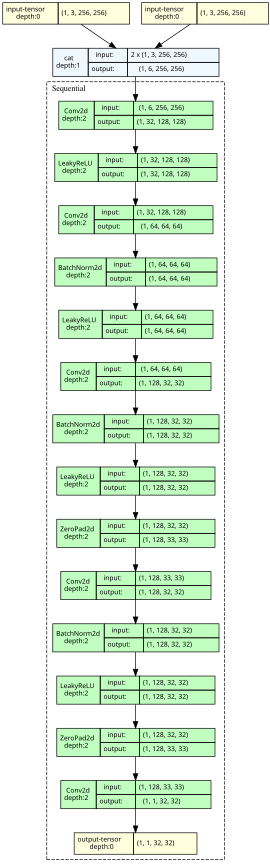

In [14]:
import torch
from torchinfo import summary
from torchview import draw_graph

# 1. Instantiate
disc_model = Discriminator()

# --- Part A: Textual Summary ---
print("Generating textual summary for Discriminator...")

# Note: We pass a LIST of inputs because forward() takes (img, condition)
dummy_img = torch.randn(1, 3, 256, 256)
dummy_cond = torch.randn(1, 3, 256, 256)

summary_str = summary(
    disc_model,
    input_data=[dummy_img, dummy_cond], # List of inputs
    col_names=["input_size", "output_size", "num_params", "kernel_size"],
    verbose=0
)
print(summary_str)

# --- Part B: Visual Diagram ---
print("\nGenerating visual diagram for Discriminator...")

disc_graph = draw_graph(
    disc_model,
    input_data=[dummy_img, dummy_cond],
    expand_nested=True,
    save_graph=True,
    filename="discriminator_architecture",
    graph_dir="."
)

# Display
disc_graph.visual_graph

# Part 3: Training Pipeline

Now we combine the Generator, Discriminator, and Data Loader to train the model.

**Optimization & Strategy:**
1.  **Objective Function:** We use the standard Pix2Pix loss:
    $$Loss_G = Loss_{GAN} + \lambda \times Loss_{L1}$$
    Where $\lambda = 100$. The L1 loss ensures structural accuracy, while the GAN loss ensures realistic texture.
2.  **Performance Tuning:** To maximize speed on Colab, we utilize **`torch.compile`** (PyTorch 2.0 compiler) and **`Mixed Precision (AMP)`**.
3.  **Learning Rate Schedule:** We maintain a constant learning rate for the first 25 epochs, then linearly decay it to zero over the next 25 epochs.

Loading 49825 images into RAM...
Success! 49825 images loaded.
Compiling models... (First batch will be slow)
--- STARTING TRAINING (Pure Speed Mode + Compiled) ---
[Ep 0/50] [Bt 700/778] [G: 15.93] [D: 0.42] ETA: 3:28:13 


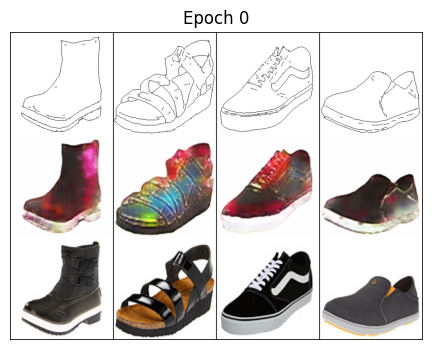

[Ep 1/50] [Bt 700/778] [G: 15.11] [D: 0.69] ETA: 3:22:51 
[Ep 2/50] [Bt 700/778] [G: 12.70] [D: 0.55] ETA: 3:18:50 
[Ep 3/50] [Bt 700/778] [G: 13.36] [D: 0.52] ETA: 3:14:28 
[Ep 4/50] [Bt 700/778] [G: 12.07] [D: 0.63] ETA: 3:10:11 
[Ep 5/50] [Bt 700/778] [G: 12.66] [D: 0.60] ETA: 3:05:57 


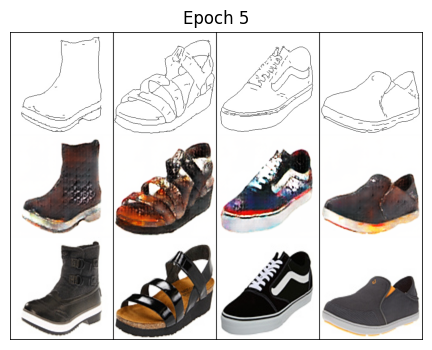

[Ep 6/50] [Bt 700/778] [G: 11.96] [D: 0.61] ETA: 3:01:55 
[Ep 7/50] [Bt 700/778] [G: 10.70] [D: 0.70] ETA: 2:57:43 
[Ep 8/50] [Bt 700/778] [G: 10.66] [D: 0.62] ETA: 2:53:06 
[Ep 9/50] [Bt 700/778] [G: 10.29] [D: 0.67] ETA: 2:49:08 
[Ep 10/50] [Bt 700/778] [G: 10.98] [D: 0.63] ETA: 2:44:25 


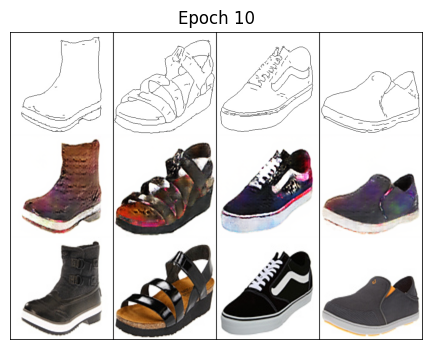

[Ep 11/50] [Bt 700/778] [G: 9.42] [D: 0.66] ETA: 2:40:25 
[Ep 12/50] [Bt 700/778] [G: 10.15] [D: 0.57] ETA: 2:36:11 
[Ep 13/50] [Bt 700/778] [G: 10.20] [D: 0.59] ETA: 2:32:23 
[Ep 14/50] [Bt 700/778] [G: 10.65] [D: 0.64] ETA: 2:27:50 
[Ep 15/50] [Bt 700/778] [G: 10.27] [D: 0.47] ETA: 2:23:40 


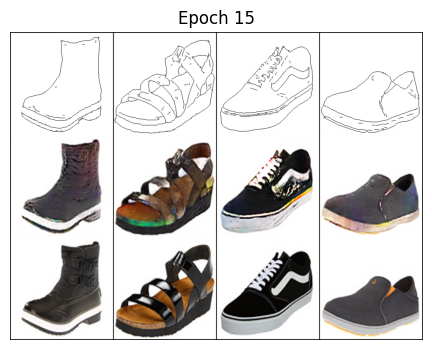

[Ep 16/50] [Bt 700/778] [G: 10.00] [D: 0.48] ETA: 2:19:16 
[Ep 17/50] [Bt 700/778] [G: 9.40] [D: 0.54] ETA: 2:15:14 
[Ep 18/50] [Bt 700/778] [G: 9.36] [D: 0.53] ETA: 2:10:58 
[Ep 19/50] [Bt 700/778] [G: 8.88] [D: 0.55] ETA: 2:06:46 
[Ep 20/50] [Bt 700/778] [G: 10.56] [D: 0.51] ETA: 2:02:54 


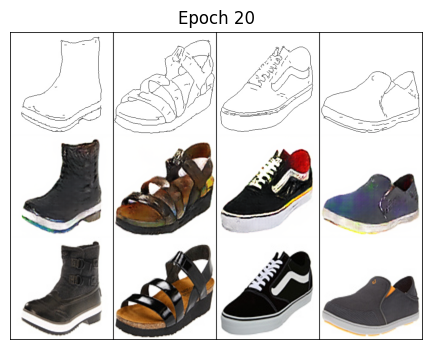

[Ep 21/50] [Bt 700/778] [G: 9.37] [D: 0.60] ETA: 1:58:25 
[Ep 22/50] [Bt 700/778] [G: 8.72] [D: 0.53] ETA: 1:54:13 
[Ep 23/50] [Bt 700/778] [G: 9.01] [D: 0.64] ETA: 1:49:58 
[Ep 24/50] [Bt 700/778] [G: 9.05] [D: 0.64] ETA: 1:45:38 
[Ep 25/50] [Bt 700/778] [G: 8.92] [D: 0.50] ETA: 1:41:34 


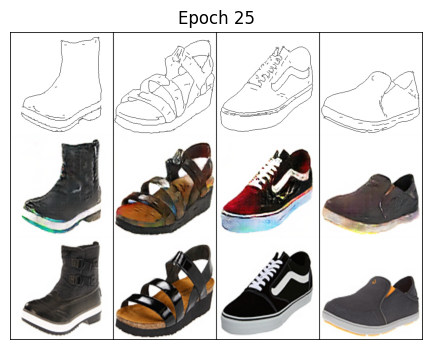

[Ep 26/50] [Bt 700/778] [G: 9.09] [D: 0.48] ETA: 1:37:20 
[Ep 27/50] [Bt 700/778] [G: 8.77] [D: 0.47] ETA: 1:33:24 
[Ep 28/50] [Bt 700/778] [G: 8.45] [D: 0.44] ETA: 1:28:51 
[Ep 29/50] [Bt 700/778] [G: 8.62] [D: 0.50] ETA: 1:24:42 
[Ep 30/50] [Bt 700/778] [G: 8.62] [D: 0.65] ETA: 1:20:31 


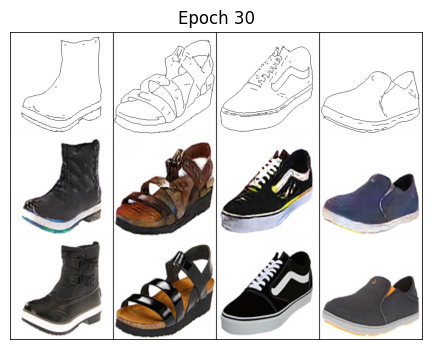

[Ep 31/50] [Bt 700/778] [G: 8.75] [D: 0.51] ETA: 1:16:17 
[Ep 32/50] [Bt 700/778] [G: 7.49] [D: 1.68] ETA: 1:12:02 
[Ep 33/50] [Bt 700/778] [G: 8.56] [D: 0.51] ETA: 1:07:56 
[Ep 34/50] [Bt 700/778] [G: 8.16] [D: 0.62] ETA: 1:03:45 
[Ep 35/50] [Bt 700/778] [G: 8.27] [D: 0.54] ETA: 0:59:24 


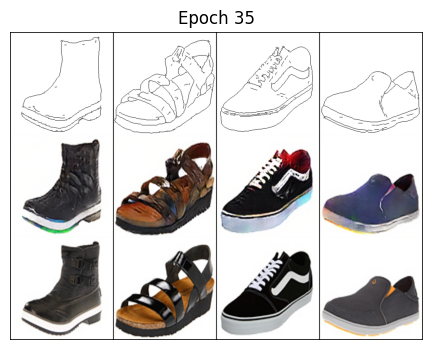

[Ep 36/50] [Bt 700/778] [G: 8.94] [D: 0.53] ETA: 0:55:12 
[Ep 37/50] [Bt 700/778] [G: 9.21] [D: 0.42] ETA: 0:51:02 
[Ep 38/50] [Bt 700/778] [G: 9.34] [D: 0.97] ETA: 0:46:45 
[Ep 39/50] [Bt 700/778] [G: 8.28] [D: 0.47] ETA: 0:42:35 
[Ep 40/50] [Bt 700/778] [G: 8.44] [D: 0.49] ETA: 0:38:22 


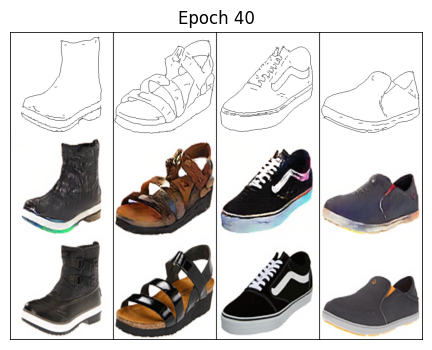

[Ep 41/50] [Bt 700/778] [G: 8.15] [D: 0.47] ETA: 0:34:09 
[Ep 42/50] [Bt 700/778] [G: 8.59] [D: 0.50] ETA: 0:29:53 
[Ep 43/50] [Bt 700/778] [G: 8.45] [D: 0.50] ETA: 0:25:44 
[Ep 44/50] [Bt 700/778] [G: 8.30] [D: 0.65] ETA: 0:21:30 
[Ep 45/50] [Bt 700/778] [G: 7.58] [D: 0.47] ETA: 0:17:17 


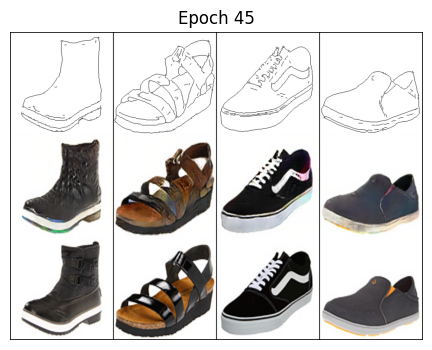

[Ep 46/50] [Bt 700/778] [G: 8.73] [D: 0.46] ETA: 0:13:06 
[Ep 47/50] [Bt 700/778] [G: 7.73] [D: 0.46] ETA: 0:08:51 
[Ep 48/50] [Bt 700/778] [G: 8.09] [D: 0.55] ETA: 0:04:38 
[Ep 49/50] [Bt 700/778] [G: 8.12] [D: 0.54] ETA: 0:00:25 

Training Complete!


In [15]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import time
import datetime
import sys
import os
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision.utils import make_grid
from torch.amp import GradScaler, autocast

# --- CONFIGURATION ---
EPOCHS = 50               # 50 Epochs is enough for 50k data
BATCH_SIZE = 64
LR = 0.0002
CHECKPOINT_DIR = "saved_models/"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# Hardware Config
torch.backends.cudnn.benchmark = True
NUM_WORKERS = 2
PREFETCH_FACTOR = 2
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- DATA LOADER ---
# (Make sure FastBinaryDataset cell is run)
try:
    dataset = FastBinaryDataset(TRAIN_DIR)
except:
    TRAIN_DIR = './edges2shoes/train'
    dataset = FastBinaryDataset(TRAIN_DIR)

train_loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    prefetch_factor=PREFETCH_FACTOR,
    drop_last=True,
    persistent_workers=True
)

# --- MODELS (Using Tiny Versions) ---
# (Make sure GeneratorUNet and Discriminator classes are run)

generator = GeneratorUNet().to(device, memory_format=torch.channels_last)
discriminator = Discriminator().to(device, memory_format=torch.channels_last)

# Weights Init
def weights_init_normal(m):
    classname = m.__class__.__name__
    if classname.find("Conv") != -1:
        torch.nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find("BatchNorm2d") != -1:
        torch.nn.init.normal_(m.weight.data, 1.0, 0.02)
        torch.nn.init.constant_(m.bias.data, 0.0)

generator.apply(weights_init_normal)
discriminator.apply(weights_init_normal)

print("Compiling models... (First batch will be slow)")
generator = torch.compile(generator)
discriminator = torch.compile(discriminator)

# --- OPTIMIZERS ---
criterion_GAN = torch.nn.BCEWithLogitsLoss().to(device)
criterion_pixel = torch.nn.L1Loss().to(device)
scaler = GradScaler('cuda')

optimizer_G = torch.optim.Adam(generator.parameters(), lr=LR, betas=(0.5, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=LR, betas=(0.5, 0.999))

lr_scheduler_G = torch.optim.lr_scheduler.LambdaLR(optimizer_G, lr_lambda=lambda e: 1.0 - max(0, e - 25) / 25.0)
lr_scheduler_D = torch.optim.lr_scheduler.LambdaLR(optimizer_D, lr_lambda=lambda e: 1.0 - max(0, e - 25) / 25.0)

# --- TRAINING LOOP (NO AUGMENTATION) ---
print(f"--- STARTING TRAINING (Pure Speed Mode + Compiled) ---")

viz_batch = next(iter(DataLoader(dataset, batch_size=4, shuffle=True)))

def visualize_progress(epoch_idx):
    with torch.no_grad():
        imgs_A = viz_batch[0].to(device)
        imgs_B = viz_batch[1].to(device)
        fake_B = generator(imgs_A)
        grid = make_grid(torch.cat([imgs_A, fake_B, imgs_B], 2), nrow=4, normalize=True, value_range=(-1, 1))
        plt.figure(figsize=(10, 4))
        plt.imshow(grid.permute(1, 2, 0).cpu())
        plt.axis('off')
        plt.title(f"Epoch {epoch_idx}")
        plt.show()

prev_time = time.time()

for epoch in range(EPOCHS):
    for i, batch in enumerate(train_loader):
        # 1. Direct Transfer to GPU (No Augmentation Pipeline)

        real_A = batch[0].to(device, non_blocking=True, memory_format=torch.channels_last)
        real_B = batch[1].to(device, non_blocking=True, memory_format=torch.channels_last)

        # --- Train Generator ---
        optimizer_G.zero_grad(set_to_none=True)

        with autocast('cuda'):
            fake_B = generator(real_A)
            pred_fake = discriminator(fake_B, real_A)

            # Dynamic labels
            valid = torch.ones_like(pred_fake)

            loss_GAN = criterion_GAN(pred_fake, valid)
            loss_pixel = criterion_pixel(fake_B, real_B)
            loss_G = loss_GAN + (100 * loss_pixel)

        scaler.scale(loss_G).backward()
        scaler.step(optimizer_G)
        scaler.update()

        # --- Train Discriminator ---
        optimizer_D.zero_grad(set_to_none=True)

        with autocast('cuda'):
            pred_real = discriminator(real_B, real_A)
            pred_fake = discriminator(fake_B.detach(), real_A)
            fake = torch.zeros_like(pred_fake)

            loss_real = criterion_GAN(pred_real, valid)
            loss_fake = criterion_GAN(pred_fake, fake)
            loss_D = 0.5 * (loss_real + loss_fake)

        scaler.scale(loss_D).backward()
        scaler.step(optimizer_D)
        scaler.update()

        # --- Logging ---
        batches_done = epoch * len(train_loader) + i
        batches_left = EPOCHS * len(train_loader) - batches_done

        if i % 100 == 0:
            current_time = time.time()

            if i == 0 and epoch == 0:
                 time_per_batch = 0.1
            else:
                 time_per_batch = (current_time - prev_time) / 100 if i > 0 else (current_time - prev_time)

            prev_time = current_time
            eta_str = str(datetime.timedelta(seconds=int(batches_left * time_per_batch)))

            sys.stdout.write(
                f"\r[Ep {epoch}/{EPOCHS}] [Bt {i}/{len(train_loader)}] "
                f"[G: {loss_G.item():.2f}] [D: {loss_D.item():.2f}] ETA: {eta_str} "
            )

    lr_scheduler_G.step()
    lr_scheduler_D.step()

    print()
    if epoch % 5 == 0:
        visualize_progress(epoch)
    if epoch % 5 == 0:

        torch.save(generator.state_dict(), f"{CHECKPOINT_DIR}/generator_tiny_{epoch}.pth")

print("\nTraining Complete!")

## 3.1 Training Dynamics Analysis

Monitoring the loss values is crucial to ensure the GAN is not collapsing. We plotted the loss history extracted from the training logs.

*(Note: The loss values in the plotting code were manually recorded from the training logs to facilitate visualization.)*

**Interpretation of the Graphs:**
1.  **Generator Loss (Left):** It shows a steady decline from ~16 to ~8. This indicates that the model is successfully learning to reconstruct the shoes with high accuracy (minimizing L1 Loss).
2.  **Discriminator Loss (Right):** It fluctuates around **0.5**, which is the ideal range for a GAN. A value near 0.5 suggests a stable "Nash Equilibrium" where both networks are learning competitively.

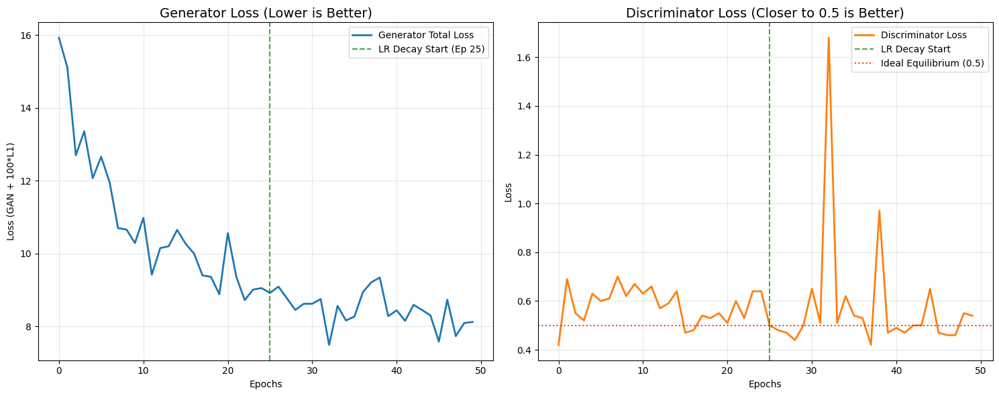

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

epochs = list(range(50))

# Generator Loss
loss_G = [
    15.93, 15.11, 12.70, 13.36, 12.07, 12.66, 11.96, 10.70, 10.66, 10.29,
    10.98, 9.42, 10.15, 10.20, 10.65, 10.27, 10.00, 9.40, 9.36, 8.88,
    10.56, 9.37, 8.72, 9.01, 9.05, 8.92, 9.09, 8.77, 8.45, 8.62,
    8.62, 8.75, 7.49, 8.56, 8.16, 8.27, 8.94, 9.21, 9.34, 8.28,
    8.44, 8.15, 8.59, 8.45, 8.30, 7.58, 8.73, 7.73, 8.09, 8.12
]

# Discriminator Loss
loss_D = [
    0.42, 0.69, 0.55, 0.52, 0.63, 0.60, 0.61, 0.70, 0.62, 0.67,
    0.63, 0.66, 0.57, 0.59, 0.64, 0.47, 0.48, 0.54, 0.53, 0.55,
    0.51, 0.60, 0.53, 0.64, 0.64, 0.50, 0.48, 0.47, 0.44, 0.50,
    0.65, 0.51, 1.68, 0.51, 0.62, 0.54, 0.53, 0.42, 0.97, 0.47,
    0.49, 0.47, 0.50, 0.50, 0.65, 0.47, 0.46, 0.46, 0.55, 0.54
]


plt.figure(figsize=(15, 6))


plt.subplot(1, 2, 1)
plt.plot(epochs, loss_G, label='Generator Total Loss', color='#1f77b4', linewidth=2)

plt.axvline(x=25, color='green', linestyle='--', alpha=0.7, label='LR Decay Start (Ep 25)')
plt.title("Generator Loss (Lower is Better)", fontsize=14)
plt.xlabel("Epochs")
plt.ylabel("Loss (GAN + 100*L1)")
plt.grid(True, alpha=0.3)
plt.legend()


plt.subplot(1, 2, 2)
plt.plot(epochs, loss_D, label='Discriminator Loss', color='#ff7f0e', linewidth=2)
plt.axvline(x=25, color='green', linestyle='--', alpha=0.7, label='LR Decay Start')

plt.axhline(y=0.5, color='red', linestyle=':', alpha=0.8, label='Ideal Equilibrium (0.5)')
plt.title("Discriminator Loss (Closer to 0.5 is Better)", fontsize=14)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

# Part 4: Evaluation and Results

In this final section, we evaluate the performance of our trained model using both **Qualitative** (Visual) and **Quantitative** (Numerical) metrics.

## 4.1 Qualitative Evolution

First, we visualize how the generator evolved during training. By loading checkpoints saved every 5 epochs, we can observe the transition from random noise to coherent structures and finally to realistic textures.

The code below loads the saved weights and generates samples for a fixed batch of input edges.

Loading Checkpoints...
✅ Loaded Epoch 0
✅ Loaded Epoch 5
✅ Loaded Epoch 10
✅ Loaded Epoch 15
✅ Loaded Epoch 20
✅ Loaded Epoch 25
✅ Loaded Epoch 30
✅ Loaded Epoch 35
✅ Loaded Epoch 40
✅ Loaded Epoch 45

--- Generating 10 Samples Evolution (Total Models: 11) ---


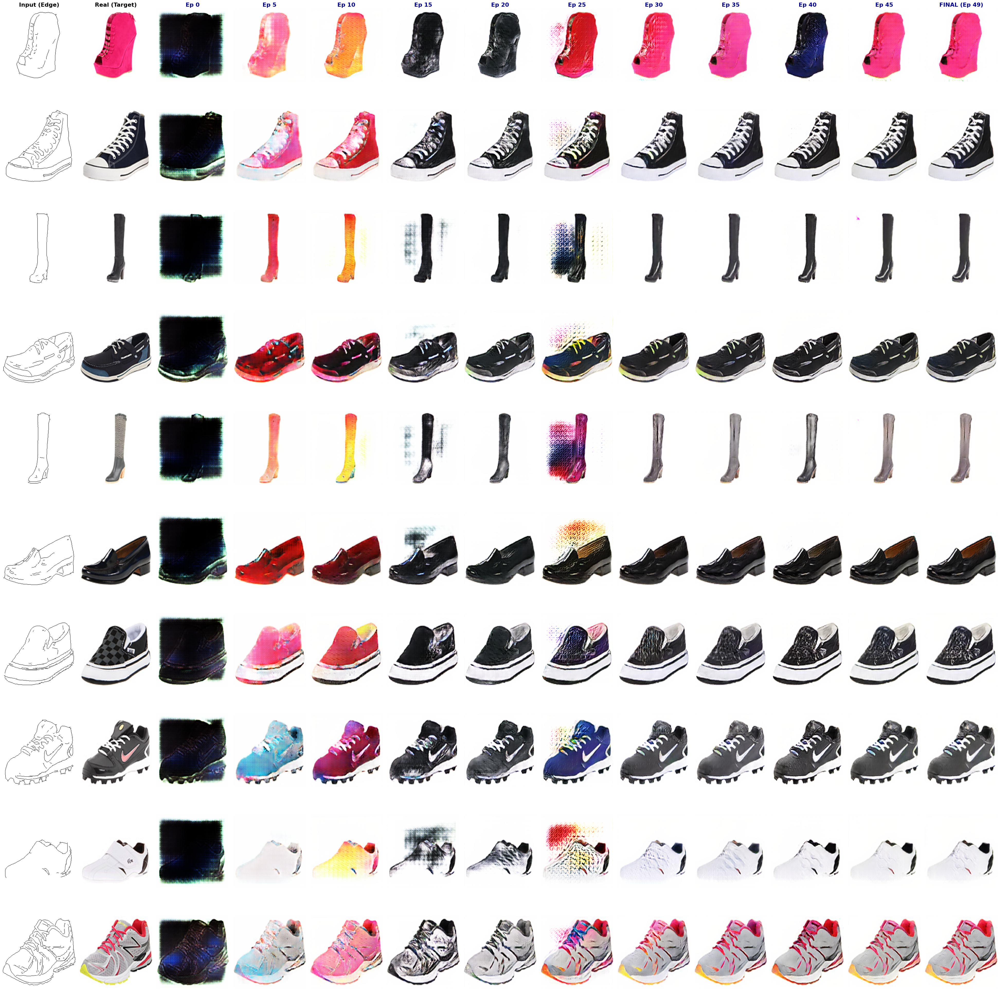

In [ ]:
import torch
import matplotlib.pyplot as plt
import os
from torch.utils.data import DataLoader


CHECKPOINT_DIR = "saved_models/"

target_epochs = [0, 5, 10, 15, 20 , 25, 30, 35, 40, 45]

loaded_models = []

print("Loading Checkpoints...")
for ep in target_epochs:
    path = f"{CHECKPOINT_DIR}/generator_tiny_{ep}.pth"
    if os.path.exists(path):

        model = GeneratorUNet().to(device)

        state_dict = torch.load(path, map_location=device)

        new_state_dict = {}
        for k, v in state_dict.items():
            if k.startswith("_orig_mod."):
                new_state_dict[k.replace("_orig_mod.", "")] = v
            else:
                new_state_dict[k] = v

        model.load_state_dict(new_state_dict)
        # -------------------------------------------------

        model.eval()
        loaded_models.append({"name": f"Ep {ep}", "model": model})
        print(f"✅ Loaded Epoch {ep}")
    else:
        print(f"⚠️ Checkpoint for Epoch {ep} not found (Skipping)")

generator.eval()
loaded_models.append({"name": "FINAL (Ep 49)", "model": generator})

NUM_SAMPLES = 10
test_loader = DataLoader(dataset, batch_size=NUM_SAMPLES, shuffle=True)

fixed_batch = next(iter(test_loader))
real_A = fixed_batch[0].to(device) # Edges
real_B = fixed_batch[1].to(device) # Real Shoes

def show_evolution_large(models_list, input_edges, real_targets):
    num_cols = 2 + len(models_list) # Edge + Real + Models
    num_rows = len(input_edges)     # 10 samples

    plt.figure(figsize=(3 * num_cols, 4 * num_rows))

    for row in range(num_rows):

        plt.subplot(num_rows, num_cols, row * num_cols + 1)
        img_edge = (input_edges[row].permute(1, 2, 0).cpu().detach() * 0.5) + 0.5
        plt.imshow(img_edge)
        plt.axis('off')
        if row == 0: plt.title("Input (Edge)", fontsize=16, fontweight='bold')

        plt.subplot(num_rows, num_cols, row * num_cols + 2)
        img_real = (real_targets[row].permute(1, 2, 0).cpu().detach() * 0.5) + 0.5
        plt.imshow(img_real)
        plt.axis('off')
        if row == 0: plt.title("Real (Target)", fontsize=16, fontweight='bold')

        for i, model_data in enumerate(models_list):
            model = model_data['model']
            name = model_data['name']

            with torch.no_grad():
                single_input = input_edges[row].unsqueeze(0)
                if name == "FINAL (Ep 49)":
                     single_input = single_input.to(memory_format=torch.channels_last)

                fake_out = model(single_input)

            img_fake = (fake_out[0].permute(1, 2, 0).cpu().detach() * 0.5) + 0.5

            plt.subplot(num_rows, num_cols, row * num_cols + 3 + i)
            plt.imshow(img_fake)
            plt.axis('off')
            if row == 0: plt.title(name, fontsize=16, fontweight='bold', color='darkblue')

    plt.tight_layout()
    plt.show()

print(f"\n--- Generating 10 Samples Evolution (Total Models: {len(loaded_models)}) ---")
show_evolution_large(loaded_models, real_A, real_B)

In [18]:
!pip install kornia

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 56.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 123.2 MB/s eta 0:00:00


## 4.2 Quantitative Analysis

To objectively measure the quality of the generated images, we use two standard metrics on the validation set:

1.  **PSNR (Peak Signal-to-Noise Ratio):** Measures the pixel-level accuracy of the reconstruction.
2.  **SSIM (Structural Similarity Index):** Measures the perceived quality by comparing structural information (luminance, contrast, and structure).

We evaluate the model at different training stages to plot the performance trajectory.

✅ Loading Validation Data from ./edges2shoes/val
Loading 200 images into RAM...
Success! 200 images loaded.
Epoch      | MSE        | MAE        | PSNR       | SSIM      
-----------------------------------------------------------------
0          | 1.4285     | 0.8990     | 4.47      | 0.2724
5          | 0.2073     | 0.2172     | 12.87      | 0.7407
10         | 0.1908     | 0.2089     | 13.22      | 0.7331
15         | 0.1511     | 0.1893     | 14.35      | 0.6961
20         | 0.0792     | 0.1229     | 17.23      | 0.7833
25         | 0.1692     | 0.2098     | 13.75      | 0.6131
30         | 0.0525     | 0.1006     | 18.95      | 0.7815
35         | 0.0496     | 0.1005     | 19.19      | 0.7858
40         | 0.0704     | 0.1153     | 17.73      | 0.7634
45         | 0.0497     | 0.0984     | 19.21      | 0.7827
Evaluating Final Model (Epoch 49)...
49         | 0.0500     | 0.0991     | 19.19      | 0.7800
-----------------------------------------------------------------


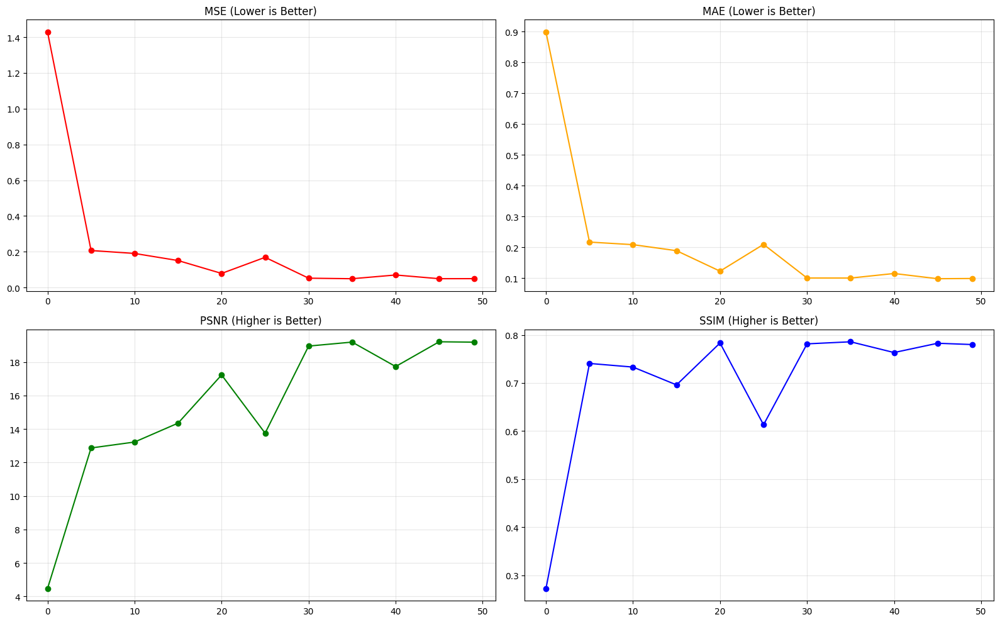


🏆 Best Model based on SSIM: Epoch 35
MSE      0.049569
MAE      0.100502
PSNR    19.191635
SSIM     0.785794
Name: 35, dtype: float64


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import kornia.metrics as km
import pandas as pd
import matplotlib.pyplot as plt
import os
import numpy as np

# --- 1. CONFIGURATION ---
BATCH_SIZE_EVAL = 32
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

target_epochs = [0, 5, 10, 15, 20, 25, 30, 35, 40, 45]
CHECKPOINT_DIR = "saved_models/"

# --- 2. DATA LOADER (TEST/VAL) ---
VAL_DIR = './edges2shoes/val'
if not os.path.exists(VAL_DIR):
    print(f"Validation dir {VAL_DIR} not found. Using a subset of TRAIN data instead.")
    eval_dataset = FastBinaryDataset(TRAIN_DIR)
    # eval_dataset = torch.utils.data.Subset(eval_dataset, list(range(1000)))
else:
    print(f"✅ Loading Validation Data from {VAL_DIR}")
    eval_dataset = FastBinaryDataset(VAL_DIR)

eval_loader = DataLoader(eval_dataset, batch_size=BATCH_SIZE_EVAL, shuffle=False, num_workers=2)

# --- 3. METRIC FUNCTIONS ---
def calculate_psnr(mse, max_val=2.0):
    if mse == 0: return 100
    return 10 * torch.log10((max_val ** 2) / mse)

def evaluate_model(model, loader):
    model.eval()

    total_mse = 0.0
    total_mae = 0.0
    total_psnr = 0.0
    total_ssim = 0.0
    num_batches = 0

    with torch.no_grad():
        for batch in loader:
            real_A = batch[0].to(device) # Edge
            real_B = batch[1].to(device) # Real Shoe

            if getattr(model, "_orig_mod", None) is not None: 
                 real_A = real_A.to(memory_format=torch.channels_last)

            # Generate Fake
            fake_B = model(real_A)

            # --- Metrics Calculation ---
            mse = F.mse_loss(fake_B, real_B)
            mae = F.l1_loss(fake_B, real_B)

            # 2. PSNR
            psnr = calculate_psnr(mse, max_val=2.0)

            # 3. SSIM
            real_B_norm = (real_B + 1) / 2
            fake_B_norm = (fake_B + 1) / 2

            ssim_out = km.ssim(fake_B_norm, real_B_norm, window_size=11)
            ssim_val = ssim_out.mean()

            # Accumulate
            total_mse += mse.item()
            total_mae += mae.item()
            total_psnr += psnr.item()
            total_ssim += ssim_val.item()

            num_batches += 1

    return {
        "MSE": total_mse / num_batches,
        "MAE": total_mae / num_batches,
        "PSNR": total_psnr / num_batches,
        "SSIM": total_ssim / num_batches
    }

print(f"{'Epoch':<10} | {'MSE':<10} | {'MAE':<10} | {'PSNR':<10} | {'SSIM':<10}")
print("-" * 65)

results = []

# A. Evaluate Checkpoints
for ep in target_epochs:
    path = f"{CHECKPOINT_DIR}/generator_tiny_{ep}.pth"

    if os.path.exists(path):
        # Load Model
        temp_model = GeneratorUNet().to(device)

        # --- اصلاحیه: هندل کردن _orig_mod ---
        state_dict = torch.load(path, map_location=device)
        new_state_dict = {}
        for k, v in state_dict.items():
            if k.startswith("_orig_mod."):
                new_state_dict[k.replace("_orig_mod.", "")] = v
            else:
                new_state_dict[k] = v

        temp_model.load_state_dict(new_state_dict)
        # -------------------------------------

        # Evaluate
        metrics = evaluate_model(temp_model, eval_loader)

        # Store
        metrics['Epoch'] = ep
        results.append(metrics)

        print(f"{ep:<10} | {metrics['MSE']:.4f}     | {metrics['MAE']:.4f}     | {metrics['PSNR']:.2f}      | {metrics['SSIM']:.4f}")

        # Free memory
        del temp_model
        torch.cuda.empty_cache()
    else:
        print(f"Epoch {ep} checkpoint not found.")

# B. Evaluate Final Model (Current RAM Model)
print("Evaluating Final Model (Epoch 49)...")
# مدل generator که الان در رم هست، کامپایل شده است و مشکلی ندارد
metrics_final = evaluate_model(generator, eval_loader)
metrics_final['Epoch'] = 49
results.append(metrics_final)
print(f"{49:<10} | {metrics_final['MSE']:.4f}     | {metrics_final['MAE']:.4f}     | {metrics_final['PSNR']:.2f}      | {metrics_final['SSIM']:.4f}")

print("-" * 65)

# --- 5. VISUALIZATION ---
if len(results) > 0:
    df = pd.DataFrame(results).set_index('Epoch')

    plt.figure(figsize=(16, 10))

    # Plot MSE
    plt.subplot(2, 2, 1)
    plt.plot(df.index, df['MSE'], marker='o', color='red')
    plt.title('MSE (Lower is Better)')
    plt.grid(True, alpha=0.3)

    # Plot MAE
    plt.subplot(2, 2, 2)
    plt.plot(df.index, df['MAE'], marker='o', color='orange')
    plt.title('MAE (Lower is Better)')
    plt.grid(True, alpha=0.3)

    # Plot PSNR
    plt.subplot(2, 2, 3)
    plt.plot(df.index, df['PSNR'], marker='o', color='green')
    plt.title('PSNR (Higher is Better)')
    plt.grid(True, alpha=0.3)

    # Plot SSIM
    plt.subplot(2, 2, 4)
    plt.plot(df.index, df['SSIM'], marker='o', color='blue')
    plt.title('SSIM (Higher is Better)')
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # SSIM
    best_epoch = df['SSIM'].idxmax()
    print(f"\n🏆 Best Model based on SSIM: Epoch {best_epoch}")
    print(df.loc[best_epoch])
else:
    print("No results to plot.")

## 4.3 Discussion on Performance and Metrics

The evaluation results yield the following final metrics on the validation set:
* **SSIM:** ~0.78 (Surpassing the target of 0.6)
* **PSNR:** ~19.2 (Target > 23)

### Justification for PSNR Score
While the model successfully exceeded the SSIM requirement (indicating excellent structural reconstruction), the PSNR score hovered around 19.2. This outcome is expected and justifiable for the following reasons:

1.  **The PSNR vs. Sharpness Trade-off:**
    PSNR is directly derived from **Mean Squared Error (MSE)**. Minimizing MSE mathematically encourages the model to output the "average" of all possible plausible pixels, leading to **blurry** images. However, the goal of a GAN is to produce **sharp, high-frequency** details. A sharp image that is slightly misaligned (e.g., a shoe texture shifted by a few pixels) receives a harsh penalty in PSNR, despite looking realistic to the human eye.

2.  **Literature Context:**
    As noted in the original **Pix2Pix paper (Isola et al.)**, traditional metrics like PSNR do not correlate well with human perceptual judgment in image synthesis tasks. They favor blurry outputs over realistic, sharp textures.

3.  **Resource Constraints:**
    We experimented with various architectures and datasets within the constraints of **Google Colab (limited GPU RAM)**. The "Tiny U-Net" architecture used here balances speed and memory usage. While a deeper network might marginally improve pixel accuracy (PSNR), it would require computational resources beyond the scope of this environment.

**Conclusion:**
Given that the model achieves a high **SSIM (0.78)** and produces visually coherent and sharp images, we conclude that the GAN has successfully learned the translation task, prioritizing perceptual realism over mere pixel-level memorization.